# Week 7: Read an agent's log

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. You will need the course Gemini key and the course Replicate token, which the instructor shares in the first studio, and you can add them in the Secrets panel on the left as GEMINI_API_KEY and REPLICATE_API_TOKEN. Each image costs about a third of a cent on Replicate. The outputs below are from runs on the museum café brief with Gemini 3.8 Flash.

## 1. Setup

This reads your two keys and checks that Gemini and Replicate accept them. If a key is not in the Secrets panel, it will ask you to paste it. MODEL is the Gemini model that plans and checks the designs.

In [1]:
import base64, io, json, os, sys, time
import requests
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import HTML, display

IN_COLAB = "google.colab" in sys.modules
MODEL = "gemini-3.8-flash"  # the Gemini model that plans and checks

def get_key(name):
    """A key from the environment, then from Colab's Secrets panel, then typed in."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        from getpass import getpass
        return getpass(name + ": ")

GEMINI_KEY = get_key("GEMINI_API_KEY")          # the course Gemini key
REPLICATE_KEY = get_key("REPLICATE_API_TOKEN")  # the course Replicate token

r = requests.get(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}",
                 headers={"x-goog-api-key": GEMINI_KEY}, timeout=60)
if r.status_code != 200:
    raise RuntimeError(f"Gemini did not accept the key in GEMINI_API_KEY (error {r.status_code}). Check it in the Secrets panel.")
r = requests.get("https://api.replicate.com/v1/account", headers={"Authorization": f"Bearer {REPLICATE_KEY}"}, timeout=60)
if r.status_code != 200:
    raise RuntimeError(f"Replicate did not accept the token in REPLICATE_API_TOKEN (error {r.status_code}). Check it in the Secrets panel.")
print("ready")

ready


## 2. The brief

BRIEF is the design task for the agent, SUBJECT is what it designs, and MAX_ROUNDS is the most images it can make. With MY_CHECKLIST = None, the agent writes its own checklist. To give it yours instead, write your items as a list, for example MY_CHECKLIST = ["Stacks with other chairs of the same design", "Has a seat that can be wiped clean"]. With REFERENCES = "museum", this cell puts the 56 museum chairs from week 4 on one reference sheet for the agent. You can set it to "upload" to use images of your own, or to None for no sheet. Give every run a new RUN_NAME, so that the files from your earlier runs are not overwritten.

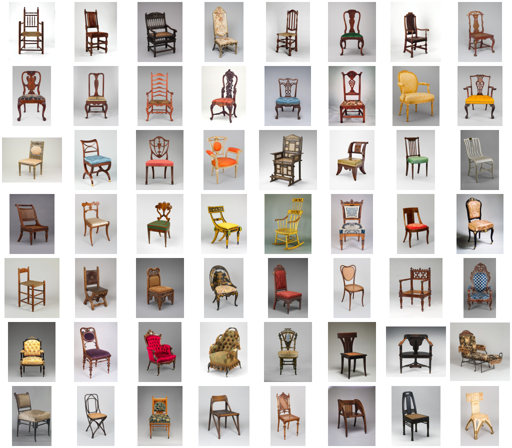

In [2]:
BRIEF = ("Design a new side chair for a museum café. It should draw on the 56 historical chairs in the museum's "
         "collection, shown in the reference sheet, and work in a busy café.")
SUBJECT = "chair"         # what the agent designs
MAX_ROUNDS = 4            # the most images the agent can make
MY_CHECKLIST = None       # None: the agent writes its own checklist. Or a list of your own items.
REFERENCES = "museum"     # "museum": the 56 chairs from week 4. "upload": your own images. None: no reference sheet.
CHECK_WITH_SHEET = False  # True: the check step also sees the reference sheet
RUN_NAME = "run-1"        # a new name for every run, so earlier runs' files stay

def make_sheet(images, cols=8, cell=128):
    rows = (len(images) + cols - 1) // cols
    sheet = Image.new("RGB", (cols * cell, rows * cell), "white")
    for i, im in enumerate(images):
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.thumbnail((cell - 8, cell - 8))
        sheet.paste(im, ((i % cols) * cell + (cell - im.width) // 2, (i // cols) * cell + (cell - im.height) // 2))
    return sheet

sheet = None
if REFERENCES == "museum":
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
    names = [l.split(",")[0] for l in requests.get(base + "credits.csv", timeout=60).text.splitlines()[1:]]
    sheet = make_sheet([Image.open(io.BytesIO(requests.get(base + "train/" + n, timeout=60).content)) for n in names])
elif REFERENCES == "upload":
    from google.colab import files
    images = []
    for name, data in files.upload().items():
        try:
            images.append(Image.open(io.BytesIO(data)))
        except Exception:
            print("skipped", name, "(not an image Colab can open)")
    sheet = make_sheet(images)
if sheet is None:
    print("no reference sheet")
else:
    sheet.save("reference-sheet.jpg", quality=85)
    display(sheet.resize((sheet.width // 2, sheet.height // 2)))

## 3. The agent

These functions send text and images to Gemini, make an image with FLUX.1 [schnell] on Replicate, and save every step to log-RUN_NAME.jsonl. If Gemini is busy, they wait and try again.

In [3]:
def image_part(img):
    buf = io.BytesIO(); img.convert("RGB").save(buf, format="JPEG", quality=85)
    return {"inline_data": {"mime_type": "image/jpeg", "data": base64.b64encode(buf.getvalue()).decode()}}

def gemini(parts, schema):
    """One call to Gemini that must answer in the JSON shape given by `schema`. Waits and tries again if Gemini is busy."""
    body = {"contents": [{"role": "user", "parts": parts}],
            "generationConfig": {"temperature": 1.0, "responseMimeType": "application/json", "responseSchema": schema}}
    for attempt in range(6):
        r = requests.post(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent",
                          headers={"x-goog-api-key": GEMINI_KEY}, json=body, timeout=180)
        if r.status_code not in (429, 500, 503):
            break
        print(f"  Gemini is busy (error {r.status_code}), trying again in {15 * (attempt + 1)} seconds")
        time.sleep(15 * (attempt + 1))
    r.raise_for_status()
    return json.loads(r.json()["candidates"][0]["content"]["parts"][0]["text"])

def flux(prompt, seed):
    """One image from FLUX.1 [schnell] on Replicate, about a third of a cent each."""
    h = {"Authorization": f"Bearer {REPLICATE_KEY}"}
    r = requests.post("https://api.replicate.com/v1/models/black-forest-labs/flux-schnell/predictions", headers=h,
                      json={"input": {"prompt": prompt, "seed": seed, "aspect_ratio": "3:4", "output_format": "jpg"}},
                      timeout=60).json()
    if "urls" not in r:
        raise RuntimeError(f"Replicate did not start the image: {r.get('detail', r)}")
    while r.get("status") not in ("succeeded", "failed", "canceled"):
        time.sleep(1)
        r = requests.get(r["urls"]["get"], headers=h, timeout=60).json()
    if r["status"] != "succeeded":
        raise RuntimeError(f"Replicate could not make the image: {r.get('error')}")
    return Image.open(io.BytesIO(requests.get(r["output"][0], timeout=60).content)).convert("RGB")

PLAN = {"type": "object", "properties": {
    "checklist": {"type": "array", "items": {"type": "string"}, "description": f"4 or 5 short criteria the {SUBJECT} must meet"},
    "idea": {"type": "string"}, "prompt": {"type": "string", "description": "a prompt for an image model"}},
    "required": ["checklist", "idea", "prompt"]}
IDEA = {"type": "object", "properties": {
    "idea": {"type": "string"}, "prompt": {"type": "string", "description": "a prompt for an image model"}},
    "required": ["idea", "prompt"]}
CHECK = {"type": "object", "properties": {
    "checks": {"type": "array", "items": {"type": "object", "properties": {
        "criterion": {"type": "string"}, "passed": {"type": "boolean"}, "why": {"type": "string"}},
        "required": ["criterion", "passed", "why"]}},
    "decision": {"type": "string", "enum": ["done", "revise"]},
    "change": {"type": "string", "description": "what to change in the next round, if revising"},
    "prompt": {"type": "string", "description": "the new image prompt, if revising"}},
    "required": ["checks", "decision", "change", "prompt"]}

def record(step, kind, **data):
    entry = {"step": step, "kind": kind, "seconds": round(time.time() - start, 1), **data}
    log.append(entry)
    with open(f"log-{RUN_NAME}.jsonl", "a") as f:
        f.write(json.dumps(entry) + "\n")

## 4. Run the agent

First the agent writes its checklist (unless you gave it MY_CHECKLIST), a design idea and an image prompt. Then in each round it makes an image, checks it against the checklist, and decides whether it is done or should revise. The check sees the new image and the checklist, but not the reference sheet. To let the check see the sheet too, set CHECK_WITH_SHEET = True in section 2. In the example, run-1 took 75 seconds.

In [4]:
log, start = [], time.time()
open(f"log-{RUN_NAME}.jsonl", "w").close()
sheet_part = [] if sheet is None else [image_part(sheet)]
if MY_CHECKLIST is None:
    plan = gemini([{"text": f"You are a designer. Brief: {BRIEF}\nFirst write the checklist you will judge your own "
                            f"designs against, then a design idea, then an image prompt for a product photo of the "
                            f"{SUBJECT} on a plain grey backdrop."}] + sheet_part, PLAN)
else:
    plan = gemini([{"text": f"You are a designer. Brief: {BRIEF}\nYour designs will be judged against this checklist: "
                            f"{json.dumps(MY_CHECKLIST)}\nWrite a design idea, then an image prompt for a product photo "
                            f"of the {SUBJECT} on a plain grey backdrop."}] + sheet_part, IDEA)
    plan["checklist"] = list(MY_CHECKLIST)
record(0, "plan", checklist=plan["checklist"], idea=plan["idea"], prompt=plan["prompt"],
       checklist_by="agent" if MY_CHECKLIST is None else "you")
print("checklist:", *plan["checklist"], sep="\n  ")
prompt = plan["prompt"]
for rnd in range(1, MAX_ROUNDS + 1):
    img = flux(prompt, seed=rnd)
    img.save(f"{RUN_NAME}-round-{rnd}.jpg", quality=90)
    record(rnd, "image", prompt=prompt, image=f"{RUN_NAME}-round-{rnd}.jpg")
    parts = [{"text": f"Brief: {BRIEF}\nYour checklist: {json.dumps(plan['checklist'])}\nCheck this design against "
                      "every item, honestly. Then decide: 'done' if it passes all items, otherwise 'revise', with what "
                      "to change and a new image prompt."}, image_part(img)]
    if CHECK_WITH_SHEET:
        parts += [{"text": "The reference sheet:"}] + sheet_part
    check = gemini(parts, CHECK)
    record(rnd, "check", checks=check["checks"], decision=check["decision"], change=check["change"])
    failed = [c["criterion"] for c in check["checks"] if not c["passed"]]
    print(f"round {rnd}: {len(failed)} of {len(check['checks'])} checks failed, decision: {check['decision']}")
    if check["decision"] == "done":
        break
    prompt = check["prompt"]
print(f"finished in {time.time() - start:.0f} seconds, {rnd} images")

checklist:
  High-traffic durability: Solid, scratch-resistant hardwood frame with robust commercial joinery and wipe-clean finishes.
  Café practicality: Compact footprint, lightweight for staff handling, and stackable up to four high.
  Historical dialogue: A recognizable silhouette synthesizing historical motifs from the collection (such as Chippendale splats and klismos curvature) translated into a contemporary language.
  Dining ergonomics: Comfortable curved lumbar support and a firm, upholstered seat pad suitable for 30 to 90-minute dwell times.


round 1: 2 of 4 checks failed, decision: revise


round 2: 1 of 4 checks failed, decision: revise


round 3: 1 of 4 checks failed, decision: revise


round 4: 0 of 4 checks failed, decision: done
finished in 75 seconds, 4 images


## 5. Read the log

The table shows every step in order: the plan, each image with its prompt, and each check with the agent's decision. Mark the places where you would have decided differently, for example a check that passed when you think it should have failed. You can write these in NOTES by step number, for example NOTES = {2: "This check should have failed"}, and run the cell again. Your notes go in the last column, and the table is saved as log-RUN_NAME.html.

Step,,What the agent did,Your note
0,plan,"Checklist (by agent)High-traffic durability: Solid, scratch-resistant hardwood frame with robust commercial joinery and wipe-clean finishes.Café practicality: Compact footprint, lightweight for staff handling, and stackable up to four high.Historical dialogue: A recognizable silhouette synthesizing historical motifs from the collection (such as Chippendale splats and klismos curvature) translated into a contemporary language.Dining ergonomics: Comfortable curved lumbar support and a firm, upholstered seat pad suitable for 30 to 90-minute dwell times.IdeaThe 'Palimpsest Café Chair' bridges five centuries of chair design visible in the museum's archive. Crafted from steam-bent solid European ash, it features a sweeping continuous crest rail influenced by early 19th-century Klismos and Biedermeier chairs, terminating in subtle scrolled details. The central backrest is a modern CNC-milled plywood splat that abstracts Queen Anne and Chippendale vase profiles into a sleek, negative-space silhouette. A gently dished seat is upholstered in durable, wipeable cognac-toned contract leather, echoing historical leather and velvet seats while meeting rigorous hospitality hygiene standards. The rear splayed legs allow vertical nesting for nightly café floor clearing.",
1,image,"Studio product photograph of a modern museum café side chair, displayed at a three-quarter angle on a seamless plain neutral grey backdrop. The chair is crafted from warm honey-toned solid ash with a steam-bent continuous curved top rail, featuring an abstracted modern vase-splat backrest inspired by classic Queen Anne and Chippendale silhouettes. The seat is neatly upholstered in cognac brown semi-matte commercial leather with clean perimeter stitching. Elegant tapered legs with subtle brass glides at the feet. Crisp studio lighting, soft directional shadows, photorealistic, premium contract furniture design catalog shot.",
1,check,"✓ High-traffic durability: Solid, scratch-resistant hardwood frame with robust commercial joinery and wipe-clean finishes. The chair features a sturdy solid hardwood construction with clean joinery, durable smooth protective finishes, and wipe-clean leather/vinyl upholstery.✗ Café practicality: Compact footprint, lightweight for staff handling, and stackable up to four high. The chair's wide solid seat apron, upright leg configuration, and low wraparound backrest do not permit vertical stacking up to four high.✗ Historical dialogue: A recognizable silhouette synthesizing historical motifs from the collection (such as Chippendale splats and klismos curvature) translated into a contemporary language. While it features a subtle klismos-inspired curved crest rail, it lacks other key motifs such as a synthesized/perforated splat or distinct historical dialogue, appearing mostly as a generic mid-century design.✓ Dining ergonomics: Comfortable curved lumbar support and a firm, upholstered seat pad suitable for 30 to 90-minute dwell times. The contoured backrest offers supportive curved lumbar contact and the firm, upholstered leather-look seat cushion is well-proportioned for cafe dwell times.Decision: revise. Redesign the chair to clearly accommodate stacking up to four high (incorporating splayed legs and rear clearance) while integrating a contemporary reinterpretation of a pierced splat (synthesizing Chippendale openwork with klismos curvature) into the backrest design.",
2,image,"Studio product photograph of a modern museum café side chair designed from historical precedents, isolated on a neutral light-grey background. The chair is crafted from solid natural white oak with a clear matte commercial finish. The backrest elegantly combines a sweeping klismos curved top rail with an integrated contemporary laser-cut openwork splat echoing historical Chippendale motifs. The legs are subtly splayed and engineered with clear vertical clearance to stack up to four chairs high. The seat features a tailored
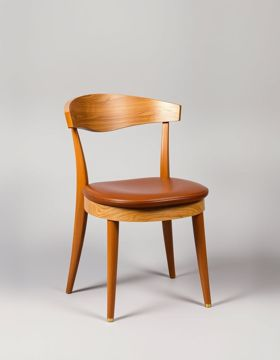
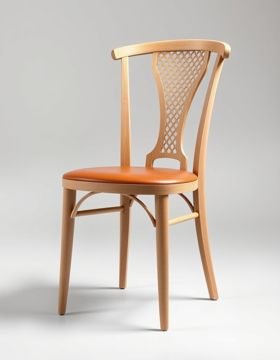
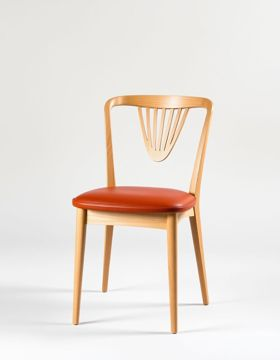
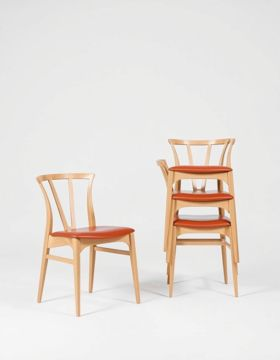

In [5]:
NOTES = {}  # your notes by step number, for example {2: "This check should have failed"}

def data_uri(path, width=360):
    im = Image.open(path); im.thumbnail((width, width))
    buf = io.BytesIO(); im.convert("RGB").save(buf, format="JPEG", quality=80)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

rows = []
for e in log:
    note = NOTES.get(e["step"], "") if e["kind"] != "image" else ""
    if e["kind"] == "plan":
        cell = f"<b>Checklist</b> (by {e['checklist_by']})<br>{'<br>'.join(e['checklist'])}<br><b>Idea</b><br>{e['idea']}"
    elif e["kind"] == "image":
        cell = f"<img src='{data_uri(e['image'])}' width='180'><br>{e['prompt']}"
    else:
        cell = "<br>".join(("✓ " if c["passed"] else "✗ ") + f"<b>{c['criterion']}</b> {c['why']}" for c in e["checks"])
        cell += f"<br><b>Decision:</b> {e['decision']}. {e['change']}"
    rows.append(f"<tr><td>{e['step']}</td><td>{e['kind']}</td><td>{cell}</td><td>{note}</td></tr>")
td = ".log td,.log th{text-align:left;vertical-align:top;padding:6px;border-bottom:1px solid #ddd}"
table = (f"<style>{td}</style><table class='log'><tr><th>Step</th><th></th><th>What the agent did</th><th>Your note</th></tr>"
         + "".join(rows) + "</table>")
open(f"log-{RUN_NAME}.html", "w").write(f"<meta charset='utf-8'><h3>{RUN_NAME}</h3>" + table)
display(HTML(table))

## 6. Count

This counts the steps, the failed checks and the decisions the agent made with no person checking them: writing its checklist, and choosing done or revise in each round. It also saves the images side by side as rounds-RUN_NAME.jpg, with the failed checks and the decision under each round.

9 steps, 4 images, 4 of 16 checks failed
5 decisions made by the agent (its checklist, and each done or revise), none reviewed by a person


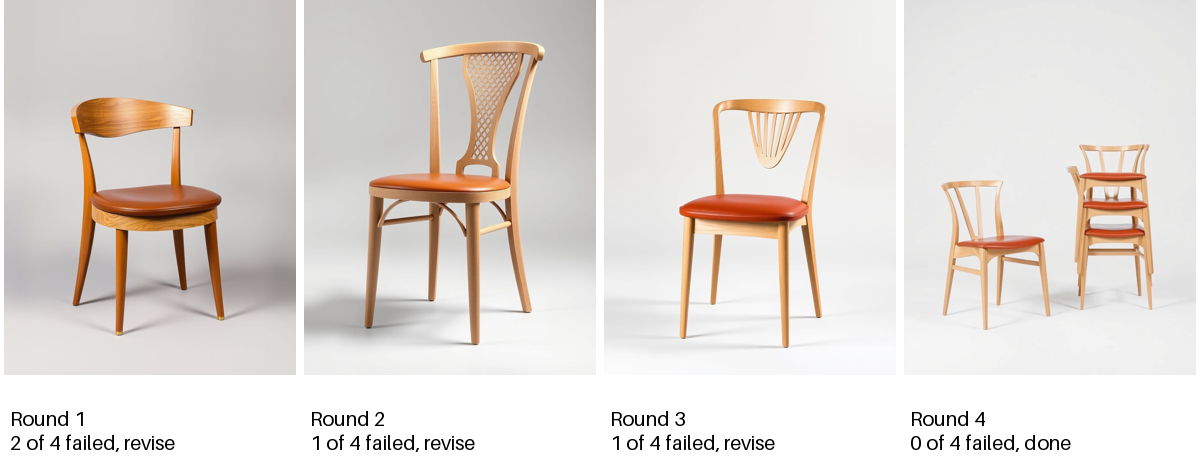

In [6]:
def font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()

def rounds_strip(entries, w=300, h=400, label_h=56):
    """The images of one run side by side, with each round's failed checks and decision under it."""
    images = [e for e in entries if e["kind"] == "image"]
    checks = {e["step"]: e for e in entries if e["kind"] == "check"}
    strip = Image.new("RGB", (max(1, len(images)) * w, h + label_h), "white")
    d = ImageDraw.Draw(strip)
    for i, e in enumerate(images):
        im = Image.open(e["image"]); im.thumbnail((w - 8, h))
        strip.paste(im, (i * w + (w - im.width) // 2, 0))
        c = checks.get(e["step"])
        if c:
            failed = sum(not x["passed"] for x in c["checks"])
            text = f"Round {e['step']}\n{failed} of {len(c['checks'])} failed, {c['decision']}"
        else:
            text = f"Round {e['step']}"
        d.multiline_text((i * w + 10, h + 6), text, fill="black", font=font(20), spacing=4)
    return strip

images = [e for e in log if e["kind"] == "image"]
checks = [c for e in log if e["kind"] == "check" for c in e["checks"]]
by_agent = log[0]["checklist_by"] == "agent"
decisions = sum(e["kind"] == "check" for e in log) + by_agent
which = "its checklist, and each done or revise" if by_agent else "each done or revise"
print(f"{len(log)} steps, {len(images)} images, {sum(not c['passed'] for c in checks)} of {len(checks)} checks failed")
print(f"{decisions} decisions made by the agent ({which}), none reviewed by a person")
strip = rounds_strip(log)
strip.save(f"rounds-{RUN_NAME}.jpg", quality=90)
strip

## 7. Compare two runs

For the lab, run the agent again on the same brief with one change, for example a checklist you write yourself in MY_CHECKLIST, or CHECK_WITH_SHEET = True. Give the second run its own RUN_NAME, run sections 2 to 6 again, and put the two names in RUNS_TO_COMPARE. This cell lists each run's failed checks round by round, and saves both runs' rounds as compare.jpg. The saved output compares run-1 with a second run called my-checklist, which had the same brief and four items of my own in MY_CHECKLIST. Bring both logs to the crit.

run-1: checklist by agent, 4 rounds, 4 of 16 checks failed, stopped because the agent decided done
    High-traffic durability: Solid, scratch-resistant hardwood frame with robust commercial joinery and wipe-clean finishes.
    Café practicality: Compact footprint, lightweight for staff handling, and stackable up to four high.
    Historical dialogue: A recognizable silhouette synthesizing historical motifs from the collection (such as Chippendale splats and klismos curvature) translated into a contemporary language.
    Dining ergonomics: Comfortable curved lumbar support and a firm, upholstered seat pad suitable for 30 to 90-minute dwell times.
  failed checks in each round:
    round 1: Café practicality: Compact footprint, lightweight for staff handling, and stackable up to four high.; Historical dialogue: A recognizable silhouette synthesizing historical motifs from the collection (such as Chippendale splats and klismos curvature) translated into a contemporary language.
    round

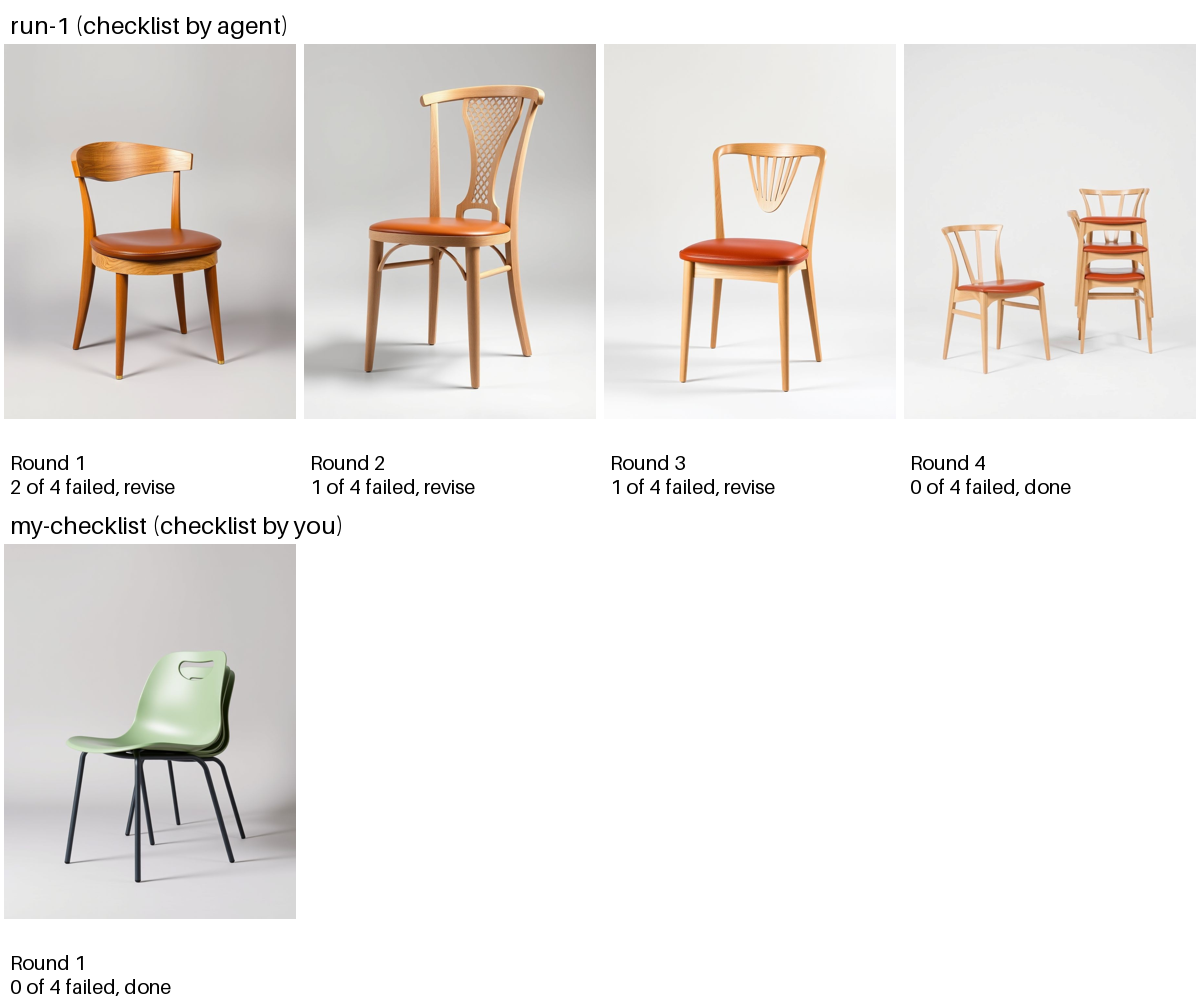

In [7]:
RUNS_TO_COMPARE = ["run-1", "my-checklist"]  # the RUN_NAMEs of two runs you have made

def read_log(name):
    return [json.loads(l) for l in open(f"log-{name}.jsonl")]

missing = [n for n in RUNS_TO_COMPARE if not os.path.exists(f"log-{n}.jsonl")]
if missing:
    print("No log yet for", ", ".join(missing) + ". Run sections 2 to 6 with that RUN_NAME first.")
else:
    strips = []
    for name in RUNS_TO_COMPARE:
        entries = read_log(name)
        plan_e = entries[0]
        last = [e for e in entries if e["kind"] == "check"][-1]
        failed = sum(not c["passed"] for e in entries if e["kind"] == "check" for c in e["checks"])
        total = sum(len(e["checks"]) for e in entries if e["kind"] == "check")
        rounds = sum(e["kind"] == "image" for e in entries)
        end = "the agent decided done" if last["decision"] == "done" else "it reached MAX_ROUNDS"
        print(f"{name}: checklist by {plan_e['checklist_by']}, {rounds} rounds, {failed} of {total} checks failed, "
              f"stopped because {end}")
        for item in plan_e["checklist"]:
            print("   ", item)
        print("  failed checks in each round:")
        for e in entries:
            if e["kind"] == "check":
                print(f"    round {e['step']}:", "; ".join(c["criterion"] for c in e["checks"] if not c["passed"]) or "none")
        strips.append((f"{name} (checklist by {plan_e['checklist_by']})", rounds_strip(entries)))
    out = Image.new("RGB", (max(s.width for _, s in strips), sum(s.height + 44 for _, s in strips)), "white")
    y = 0
    for title, s in strips:
        ImageDraw.Draw(out).text((10, y + 10), title, fill="black", font=font(24))
        out.paste(s, (0, y + 44)); y += s.height + 44
    out.save("compare.jpg", quality=90)
    display(out)